# Round Win Probability — Visualisation Notebook

Generate per-tick CT win probability traces for any processed match,
using checkpoints trained in `training_notebook.ipynb`.

**Usage:**
1. Set `MAP_NAME` and `CHECKPOINT_DIR` in **Section 1**.
2. Toggle which models to include in **Section 2** (`MODELS_TO_RUN`).
3. Run **Section 3** to load the processed match data.
4. Set `MATCH_KEY` and `ROUND_NUM` in **Section 4** and run to plot.

The notebook works on *any* processed match — including matches from outside
the train/val/test split (e.g. a game that happened yesterday), as long as
the match has been processed with the standard pipeline and saved to the
`data/<map_name>/` directory.


## 1. Imports & Config

In [1]:
!pip install torch_geometric -q

import warnings, random
from pathlib import Path

import numpy as np
import pandas as pd
import scipy.optimize
import torch
import torch.nn as nn
import torch.nn.functional as F
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
import lightgbm as lgb
from torch_geometric.data import Data, Batch
from torch_geometric.nn import GCNConv, GATConv, global_mean_pool, BatchNorm
from torch_geometric.utils import dropout_edge

from google.colab import drive
drive.mount('/content/drive')

import sys
BASE = Path('/content/drive/MyDrive/magisterka')
sys.path.insert(0, str(BASE))

from dataset import load_processed_matches, SetNormaliser

warnings.filterwarnings('ignore')
SEED = 42
random.seed(SEED); np.random.seed(SEED); torch.manual_seed(SEED)
DEVICE = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print(f'Device: {DEVICE}')


     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 64.4/64.4 kB 3.1 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.3/1.3 MB 16.0 MB/s eta 0:00:00
Mounted at /content/drive
Device: cpu


In [2]:
# ── MAP CONFIGURATION ─────────────────────────────────────────────────────
# Change MAP_NAME to the map you want to visualise.
# CHECKPOINT_DIR must point to the folder containing the trained checkpoints
# and the normaliser.npz file for that map.

MAP_NAME       = 'dust2'   # e.g. 'dust2', 'mirage', 'nuke', 'inferno', ...
CHECKPOINT_DIR = BASE / 'checkpoints' / MAP_NAME
DATA_DIR       = BASE / 'data'        / MAP_NAME

# tau for the HP-diff baseline — loaded from checkpoint or re-fitted below.
# Set to None to re-fit on the fly (requires val data). If you set a value
# here (e.g. from the training summary), the val data is not needed.
TAU_OVERRIDE = None   # e.g. 76.70 for mirage, 82.27 for inferno

# GRAPH_CFG hidden dim — must match what the checkpoint was trained with.
# Check training_summary_<map>.md for the correct value.
GRAPH_HIDDEN = 32     # use 32 for de_inferno

print(f'Map:            de_{MAP_NAME}')
print(f'Checkpoint dir: {CHECKPOINT_DIR}')
print(f'Data dir:       {DATA_DIR}')
print(f'Graph hidden:   {GRAPH_HIDDEN}')


Map:            de_dust2
Checkpoint dir: /content/drive/MyDrive/magisterka/checkpoints/dust2
Data dir:       /content/drive/MyDrive/magisterka/data/dust2
Graph hidden:   32


## 2. Model Selection

Toggle models on/off here. Only enabled models will be loaded and plotted.

In [3]:
# Set True/False to include or exclude each model from the visualisation.
MODELS_TO_RUN = {
    'HP-diff':       False,   # health-difference sigmoid baseline
    'LightGBM':      False,   # gradient-boosted tree
    'DeepSets':      False,  # permutation-invariant set model
    'SetTransformer':False,  # attention-based set model
    'GCNSimple32':     False,   # graph convolutional network
    'GAT32':           True,  # graph attention network
    # 'GCNSimple32':     True,   # graph convolutional network
}

# Plot colours — consistent with training notebook
COLORS = {
    'HP-diff':        'silver',
    'LightGBM':       '#1f77b4',
    'DeepSets':       '#ff7f0e',
    'SetTransformer': '#2ca02c',
    'GCNSimple32':      '#d62728',
    'GAT32':            '#9467bd',
}

enabled = [m for m, v in MODELS_TO_RUN.items() if v]
print('Enabled models:', enabled)


Enabled models: ['GAT32']


## 3. Model Definitions & Loading

Run once per session. Loads only the models enabled in Section 2.

In [4]:
# ── Model class definitions ───────────────────────────────────────────────
# Copied verbatim from training_notebook.ipynb so checkpoints load correctly.

class DeepSets(nn.Module):
    def __init__(self, in_features=32, hidden=128, dropout=0.3):
        super().__init__()
        self.phi = nn.Sequential(
            nn.Linear(in_features, hidden), nn.ReLU(),
            nn.Dropout(dropout), nn.Linear(hidden, hidden),
        )
        self.rho = nn.Sequential(
            nn.Linear(hidden, hidden), nn.ReLU(),
            nn.Dropout(dropout), nn.Linear(hidden, 1),
        )
    def forward(self, x):
        return self.rho(self.phi(x).mean(dim=1))


class MAB(nn.Module):
    def __init__(self, hidden, num_heads):
        super().__init__()
        self.attn  = nn.MultiheadAttention(hidden, num_heads, batch_first=True)
        self.norm1 = nn.LayerNorm(hidden)
        self.norm2 = nn.LayerNorm(hidden)
        self.ff = nn.Sequential(
            nn.Linear(hidden, hidden),   # was hidden * 4
            nn.ReLU(),
            nn.Dropout(0.1),
            nn.Linear(hidden, hidden),   # was hidden * 4
        )

    def forward(self, Q, K):
        x = self.norm1(Q + self.attn(Q, K, K)[0])
        return self.norm2(x + self.ff(x))


class ISAB(nn.Module):
    def __init__(self, hidden, num_heads, num_inds):
        super().__init__()
        self.I    = nn.Parameter(torch.randn(1, num_inds, hidden))
        self.mab0 = MAB(hidden, num_heads)
        self.mab1 = MAB(hidden, num_heads)

    def forward(self, X):
        H = self.mab0(self.I.expand(X.size(0), -1, -1), X)
        return self.mab1(X, H)


class PMA(nn.Module):
    def __init__(self, hidden, num_heads, num_seeds):
        super().__init__()
        self.S   = nn.Parameter(torch.randn(1, num_seeds, hidden))
        self.mab = MAB(hidden, num_heads)

    def forward(self, X):
        return self.mab(self.S.expand(X.size(0), -1, -1), X)


class SetTransformer(nn.Module):
    def __init__(self, hidden=128, num_heads=4, num_inds=4, num_seeds=1, in_features=32, out_features=1):
        super().__init__()
        self.embed   = nn.Linear(in_features, hidden)   # adjust in_features to match your input dim
        self.encoder = ISAB(hidden, num_heads, num_inds)
        self.decoder = PMA(hidden, num_heads, num_seeds)
        self.head    = nn.Sequential(
            nn.Identity(),           # head.0 — placeholder so head.1 aligns
            nn.Linear(hidden, out_features),
        )

    def forward(self, X):          # X: (B, N, in_features)
        X = self.embed(X)          # ← this line must be here
        X = self.encoder(X)
        X = self.decoder(X)
        return self.head(X.squeeze(1))


class GCNSimple(nn.Module):
    def __init__(self, hidden=32, num_node_features=32, dropout=0.5, drop_edge_p=0.5):
        super().__init__()
        self.drop_edge_p = drop_edge_p
        self.conv1 = GCNConv(num_node_features + 2, hidden)
        self.bn1   = BatchNorm(hidden)
        self.conv2 = GCNConv(hidden, hidden)
        self.bn2   = BatchNorm(hidden)
        self.mlp   = nn.Sequential(
            nn.Linear(hidden, hidden), nn.ReLU(),
            nn.Dropout(dropout), nn.Linear(hidden, 1),
        )
    def forward(self, data):
        x, ei, ea, batch = data.x, data.edge_index, data.edge_attr, data.batch
        n = x.size(0)
        src = ei[0]
        vis_agg  = torch.zeros(n, 1, device=x.device)
        team_agg = torch.zeros(n, 1, device=x.device)
        count    = torch.zeros(n, 1, device=x.device)
        ones     = torch.ones(src.size(0), 1, device=x.device)
        vis_agg.scatter_add_(0, src.unsqueeze(1), ea[:, 1].unsqueeze(1))
        team_agg.scatter_add_(0, src.unsqueeze(1), ea[:, 2].unsqueeze(1))
        count.scatter_add_(0, src.unsqueeze(1), ones)
        count = count.clamp(min=1)
        x_aug = torch.cat([x, vis_agg / count, team_agg / count], dim=1)
        ew = ea[:, 0].clamp(max=10.0)
        x_aug = F.relu(self.bn1(self.conv1(x_aug, ei, ew)))
        x_aug = F.relu(self.bn2(self.conv2(x_aug, ei, ew)))
        return self.mlp(global_mean_pool(x_aug, batch))


class GAT(nn.Module):
    def __init__(self, hidden=32, num_node_features=32, num_edge_features=3,
                 heads=4, dropout=0.5, drop_edge_p=0.5):
        super().__init__()
        self.drop_edge_p = drop_edge_p
        head_dim = hidden // heads
        self.conv1 = GATConv(num_node_features, head_dim, heads=heads,
                             edge_dim=num_edge_features, concat=True, dropout=dropout)
        self.bn1   = BatchNorm(hidden)
        self.conv2 = GATConv(hidden, head_dim, heads=heads,
                             edge_dim=num_edge_features, concat=True, dropout=dropout)
        self.bn2   = BatchNorm(hidden)
        self.mlp   = nn.Sequential(
            nn.Linear(hidden, hidden), nn.ReLU(),
            nn.Dropout(dropout), nn.Linear(hidden, 1),
        )
    def forward(self, data):
        x, ei, ea, batch = data.x, data.edge_index, data.edge_attr, data.batch
        x = F.relu(self.bn1(self.conv1(x, ei, ea)))
        x = F.relu(self.bn2(self.conv2(x, ei, ea)))
        return self.mlp(global_mean_pool(x, batch))


In [5]:
class GCNSimple(nn.Module):
    """
    ablation_mode controls which edge features are active:
      'full'          — distance weight + visibility + same_team (default)
      'distance_only' — distance weight only; vis/same_team zeroed out
      'no_edges'      — all edge weights set to 1.0 (uniform); no node augmentation
    """
    def __init__(self, hidden=64, num_node_features=32,
                 dropout=0.5, drop_edge_p=0.5, ablation_mode='full'):
        super().__init__()
        self.drop_edge_p   = drop_edge_p
        self.ablation_mode = ablation_mode

        # no_edges skips node augmentation, so input dim stays at num_node_features
        in_dim = num_node_features if ablation_mode == 'no_edges' else num_node_features + 2

        self.conv1 = GCNConv(in_dim, hidden)
        self.bn1   = BatchNorm(hidden)
        self.conv2 = GCNConv(hidden, hidden)
        self.bn2   = BatchNorm(hidden)
        self.mlp   = nn.Sequential(
            nn.Linear(hidden, hidden), nn.ReLU(),
            nn.Dropout(dropout),
            nn.Linear(hidden, 1),
        )

    def forward(self, data):
        x, ei, ea, batch = data.x, data.edge_index, data.edge_attr, data.batch
        if self.training:
            ei, edge_mask = dropout_edge(ei, p=self.drop_edge_p, training=True)
            ea = ea[edge_mask]
        n = x.size(0)

        if self.ablation_mode == 'no_edges':
            # Uniform edge weights — no relational signal, just graph structure
            ew   = torch.ones(ei.size(1), device=x.device)
            x_in = x
        else:
            src = ei[0]
            if self.ablation_mode == 'distance_only':
                # Zero out vis and same_team before aggregation
                vis_vals  = torch.zeros(ea.size(0), 1, device=x.device)
                team_vals = torch.zeros(ea.size(0), 1, device=x.device)
            else:  # 'full'
                vis_vals  = ea[:, 1].unsqueeze(1)
                team_vals = ea[:, 2].unsqueeze(1)

            vis_agg  = torch.zeros(n, 1, device=x.device)
            team_agg = torch.zeros(n, 1, device=x.device)
            count    = torch.zeros(n, 1, device=x.device)
            ones     = torch.ones(src.size(0), 1, device=x.device)
            vis_agg.scatter_add_(0,  src.unsqueeze(1), vis_vals)
            team_agg.scatter_add_(0, src.unsqueeze(1), team_vals)
            count.scatter_add_(0,    src.unsqueeze(1), ones)
            count = count.clamp(min=1)
            x_in = torch.cat([x, vis_agg / count, team_agg / count], dim=1)
            ew   = ea[:, 0].clamp(max=10.0)

        x_in = F.relu(self.bn1(self.conv1(x_in, ei, ew)))
        x_in = F.relu(self.bn2(self.conv2(x_in, ei, ew)))
        return self.mlp(global_mean_pool(x_in, batch))

In [6]:
# ── Load normaliser ───────────────────────────────────────────────────────
normaliser = SetNormaliser()
normaliser.load(str(CHECKPOINT_DIR / 'normaliser.npz'))
print('Normaliser loaded.')

# ── Load enabled models ───────────────────────────────────────────────────
loaded_models = {}

if MODELS_TO_RUN.get('LightGBM'):
    lgbm_model = lgb.Booster(model_file=str(CHECKPOINT_DIR / 'lightgbm.txt'))
    loaded_models['LightGBM'] = lgbm_model
    print('LightGBM loaded.')

if MODELS_TO_RUN.get('DeepSets'):
    m = DeepSets(hidden=128).to(DEVICE)
    m.load_state_dict(torch.load(CHECKPOINT_DIR / 'deepsets.pt', map_location=DEVICE))
    m.eval(); loaded_models['DeepSets'] = m
    print('DeepSets loaded.')

if MODELS_TO_RUN.get('SetTransformer'):
    m = SetTransformer(hidden=128, num_heads=4).to(DEVICE)
    m.load_state_dict(torch.load(CHECKPOINT_DIR / 'settransformer.pt', map_location=DEVICE))
    m.eval(); loaded_models['SetTransformer'] = m
    print('SetTransformer loaded.')

if MODELS_TO_RUN.get('GCNSimple32'):
    m = GCNSimple(hidden=32, dropout=0.5, drop_edge_p=0.5).to(DEVICE)
    m.load_state_dict(torch.load(CHECKPOINT_DIR / 'gcn_simple_32.pt', map_location=DEVICE))
    m.eval(); loaded_models['GCNSimple32'] = m
    print('GCNSimple loaded.')

if MODELS_TO_RUN.get('GAT32'):
    m = GAT(hidden=32, dropout=0.3, drop_edge_p=0.5).to(DEVICE)
    m.load_state_dict(torch.load(CHECKPOINT_DIR / 'gat_32.pt', map_location=DEVICE))
    m.eval(); loaded_models['GAT32'] = m
    print('GAT loaded.')

print(f'\nLoaded: {list(loaded_models.keys())}')


Normaliser loaded.
GAT loaded.

Loaded: ['GAT32']


In [ ]:
m = GCNSimple(hidden=32, dropout=0.5, drop_edge_p=0.5,ablation_mode   = 'no_edges',).to(DEVICE)
m.load_state_dict(torch.load(CHECKPOINT_DIR / 'gcn_simple_32_no_edges.pt', map_location=DEVICE))
m.eval(); loaded_models['GCNSimple32_no_edges'] = m
print('GCNSimple without edges loaded.')

GCNSimple without edges loaded.


In [ ]:
m = GCNSimple(hidden=32, dropout=0.5, drop_edge_p=0.5,ablation_mode   = 'distance_only',).to(DEVICE)
m.load_state_dict(torch.load(CHECKPOINT_DIR / 'gcn_simple_32_dist_only.pt', map_location=DEVICE))
m.eval(); loaded_models['GCNSimple32_dist_only'] = m
print('GCNSimple without edges loaded.')

GCNSimple without edges loaded.


## 4. Load Match Data

Point `SEASON_DIR` to whichever season folder contains your match.
For a brand-new match (e.g. yesterday's game), process it with the standard
pipeline and place it in the appropriate season folder, then load it here.


In [7]:
# ── Point to the season containing your match ─────────────────────────────
# Use 'season1', 'season2', or a custom folder name if you've processed
# a new match and placed it elsewhere.
SEASON_NAME = 'current'   # change as needed
SEASON_DIR  = DATA_DIR / SEASON_NAME

all_matches = load_processed_matches(SEASON_DIR)
print(f'Loaded {len(all_matches)} matches from {SEASON_DIR}')
print('\nAvailable match keys (first 20):')
for k in list(all_matches.keys())[:20]:
    rounds_in_match = len(set(
        row.get('roundNum') for row in all_matches[k]['df']
        if row.get('roundNum') is not None
    ))
    print(f'  {k}  ({rounds_in_match} rounds)')


Loaded 2 matches from /content/drive/MyDrive/magisterka/data/dust2/current

Available match keys (first 20):
  StarLadder Major Stage 3_3dmax-vs-faze-m1-dust2  (19 rounds)
  falcons-vs-spirit-m3-dust2  (1 rounds)


In [ ]:
# ── TAU for HP-diff ───────────────────────────────────────────────────────
# Using TAU_OVERRIDE if set, otherwise prints a reminder.
if TAU_OVERRIDE is not None:
    tau_opt = TAU_OVERRIDE
    print(f'Using TAU_OVERRIDE = {tau_opt:.2f}')
else:
    # Fallback: set tau to 75.0 (reasonable cross-map average) and warn.
    tau_opt = 75.0
    print(f'WARNING: TAU_OVERRIDE not set. Using default tau={tau_opt}.')
    print('Set TAU_OVERRIDE in Section 1 to the value from training_summary_<map>.md')
    print('for accurate HP-diff predictions.')


Set TAU_OVERRIDE in Section 1 to the value from training_summary_<map>.md
for accurate HP-diff predictions.


## 5. Plot Round Trace

Set `MATCH_KEY` (copy from the list above) and `ROUND_NUM`, then run.
Re-run this cell with different values to explore different rounds.


In [8]:
# ── SELECT MATCH AND ROUND ────────────────────────────────────────────────
MATCH_KEY = list(all_matches.keys())[0]
ROUND_NUM = 12

match     = all_matches[MATCH_KEY]

# ── FIX: exclude freeze-time states (secondsSincePhaseStart resets to 0
#         at the start of the live phase; freeze states have isFreezePeriod=True
#         OR can be detected as the initial block where t goes 0→~20 before
#         resetting again). The pipeline used during training strips these;
#         load_processed_matches on raw data does not.
round_idx = [
    i for i, row in enumerate(match['df'])
    if row.get('roundNum') == ROUND_NUM
    and not row.get('isFreezePeriod', False)   # ← drop freeze-time ticks
]

if not round_idx:
    raise ValueError(f'Round {ROUND_NUM} not found in {MATCH_KEY}. '
                     f'Available rounds: {sorted(set(r.get("roundNum") for r in match["df"]))}')

# Time axis: same logic as training notebook — works correctly once
# freeze states are excluded, because secondsSincePhaseStart is then
# monotonically increasing from 0 through the live phase.
preplant_dur = max(
    (float(match['df'][i].get('secondsSincePhaseStart', 0))
     for i in round_idx if not match['df'][i].get('bombPlanted', 0)),
    default=0.0
)
times = []
for i in round_idx:
    t    = float(match['df'][i].get('secondsSincePhaseStart', 0))
    bomb = int(match['df'][i].get('bombPlanted', 0))
    times.append(preplant_dur + t if bomb else t)

bombs     = [int(match['df'][i].get('bombPlanted', 0)) for i in round_idx]
y_true    = int(match['Y'][round_idx[0]])
plant_time = preplant_dur if any(bombs) else None

print(f'Match:  {MATCH_KEY}')
print(f'Round:  {ROUND_NUM}  |  Outcome: {"CT win" if y_true else "T win"}')
print(f'States: {len(round_idx)}  |  Bomb planted: {any(bombs)}')
if plant_time:
    print(f'Plant time: {plant_time:.1f}s')

Match:  StarLadder Major Stage 3_3dmax-vs-faze-m1-dust2
Round:  12  |  Outcome: T win
States: 109  |  Bomb planted: True
Plant time: 42.0s


In [9]:
# ── Inference — all enabled models ────────────────────────────────────────
data = np.load(CHECKPOINT_DIR / 'normaliser.npz')
normaliser.mean = data['mean']   # use whatever key names print() showed
normaliser.std  = data['std']
trace = {}   # model_name -> np.array of CT win probabilities

# HP-diff
if MODELS_TO_RUN.get('HP-diff'):
    X_round = pd.DataFrame([match['df'][i] for i in round_idx])
    delta_h  = X_round['ctHp'].values - X_round['tHp'].values
    trace['HP-diff'] = np.clip(1 / (1 + np.exp(-delta_h / tau_opt)), 1e-7, 1-1e-7)

# LightGBM
if MODELS_TO_RUN.get('LightGBM') and 'LightGBM' in loaded_models:
    X_round = pd.DataFrame([match['df'][i] for i in round_idx])
    drop_cols = [c for c in ['tick', 'roundNum', 'ctWin'] if c in X_round.columns]
    X_round   = X_round.drop(columns=drop_cols).fillna(0)
    trace['LightGBM'] = loaded_models['LightGBM'].predict(X_round)

# Set models (DeepSets, SetTransformer)
for name in ['DeepSets', 'SetTransformer']:
    if MODELS_TO_RUN.get(name) and name in loaded_models:
        model = loaded_models[name]
        preds = []
        with torch.no_grad():
            for i in round_idx:
                x_raw  = np.array(match['X'][i], dtype=np.float32)
                x_norm = normaliser.transform(x_raw)
                xb     = torch.tensor(x_norm, dtype=torch.float32).unsqueeze(0).to(DEVICE)
                preds.append(torch.sigmoid(model(xb)).item())
        trace[name] = np.array(preds)

# Graph models (GCNSimple, GAT)
for name in [ 'GAT32']:
    if name in loaded_models:
        model = loaded_models[name]
        preds = []
        with torch.no_grad():
            for i in round_idx:
                g = match['GNN'][i]
                data = Data(
                    x          = torch.tensor(g['x'],          dtype=torch.float32),
                    edge_index = torch.tensor(g['edge_index'],  dtype=torch.long),
                    edge_attr  = torch.tensor(g['edge_attr'],   dtype=torch.float32),
                )
                batch_data = Batch.from_data_list([data]).to(DEVICE)
                preds.append(torch.sigmoid(model(batch_data)).item())
        trace[name] = np.array(preds)

print('Inference complete.')
for name, probs in trace.items():
    final = probs[-1]
    print(f'  {name:<16}  final prob = {final:.3f}  ({"correct" if (final > 0.5) == y_true else "wrong"})')


Inference complete.
  GAT32             final prob = 0.374  (correct)


In [ ]:
print(sd['encoder.mab0.attn.in_proj_weight'].shape)  # → (3*hidden, hidden)
# e.g. (384, 128) means hidden=128 ✓
# e.g. (96,   32) means hidden=32

torch.Size([384, 128])


In [ ]:
MODELS_TO_RUN = {
    'HP-diff':       False,   # health-difference sigmoid baseline
    'LightGBM':      True,   # gradient-boosted tree
    'DeepSets':      False,  # permutation-invariant set model
    'SetTransformer':False,  # attention-based set model
    'GCNSimple32':     False,   # graph convolutional network
    'GAT32':           True,  # graph attention network
    'GCNSimple32_no_edges':     False,
    'GCNSimple32_dist_only':     False,
}

# Plot colours — consistent with training notebook
COLORS = {
    'HP-diff':        'silver',
    'LightGBM':       '#1f77b4',
    'GAT32':       '#ff7f0e',
    'GCNSimple32_dist_only': '#2ca02c',
    'GCNSimple32':      '#d62728',
    'GCNSimple32_no_edges':            '#9467bd',
}

In [10]:
import pandas as pd

KILLS_CSV = f'{DATA_DIR}/{SEASON_NAME}/falcons-vs-spirit/kills.csv'   # adjust path if your folders differ
ROUNDS_CSV = f'{DATA_DIR}/{SEASON_NAME}/falcons-vs-spirit/rounds.csv'

# t=0 reference for the x-axis (same as the game-state ticks): freeze_end
_rounds = pd.read_csv(ROUNDS_CSV)
FREEZE_END = int(_rounds.loc[_rounds['round_num'] == ROUND_NUM, 'freeze_end'].iloc[0])
TICKS_PER_SECOND = 64

_k = pd.read_csv(KILLS_CSV)
_k = _k[_k['round_num'] == ROUND_NUM]

kills = pd.DataFrame({
    'time':     (_k['tick'] - FREEZE_END) / TICKS_PER_SECOND,
    'attacker': _k['attacker_name'],
    'victim':   _k['victim_name'],
    'side':     _k['attacker_side'],          # 'ct' or 't' — who got the kill
    'weapon':   _k['weapon'],
    'headshot': _k['headshot'],
}).sort_values('time').reset_index(drop=True)

print(kills)


        time  attacker    victim side weapon  headshot
0  18.234375  kyousuke      donk    t   ak47      True
1  20.312500      tN1R     TeSeS   ct   m4a1      True
2  32.843750  kyousuke    zont1x    t   ak47      True
3  67.515625      NiKo     sh1ro    t   ak47     False
4  69.859375    magixx  karrigan   ct   ak47     False
5  72.531250      tN1R      NiKo   ct   m4a1     False
6  75.468750    magixx    m0NESY   ct   ak47     False
7  75.640625  kyousuke    magixx    t   ak47     False
8  76.734375      tN1R  kyousuke   ct   m4a1     False


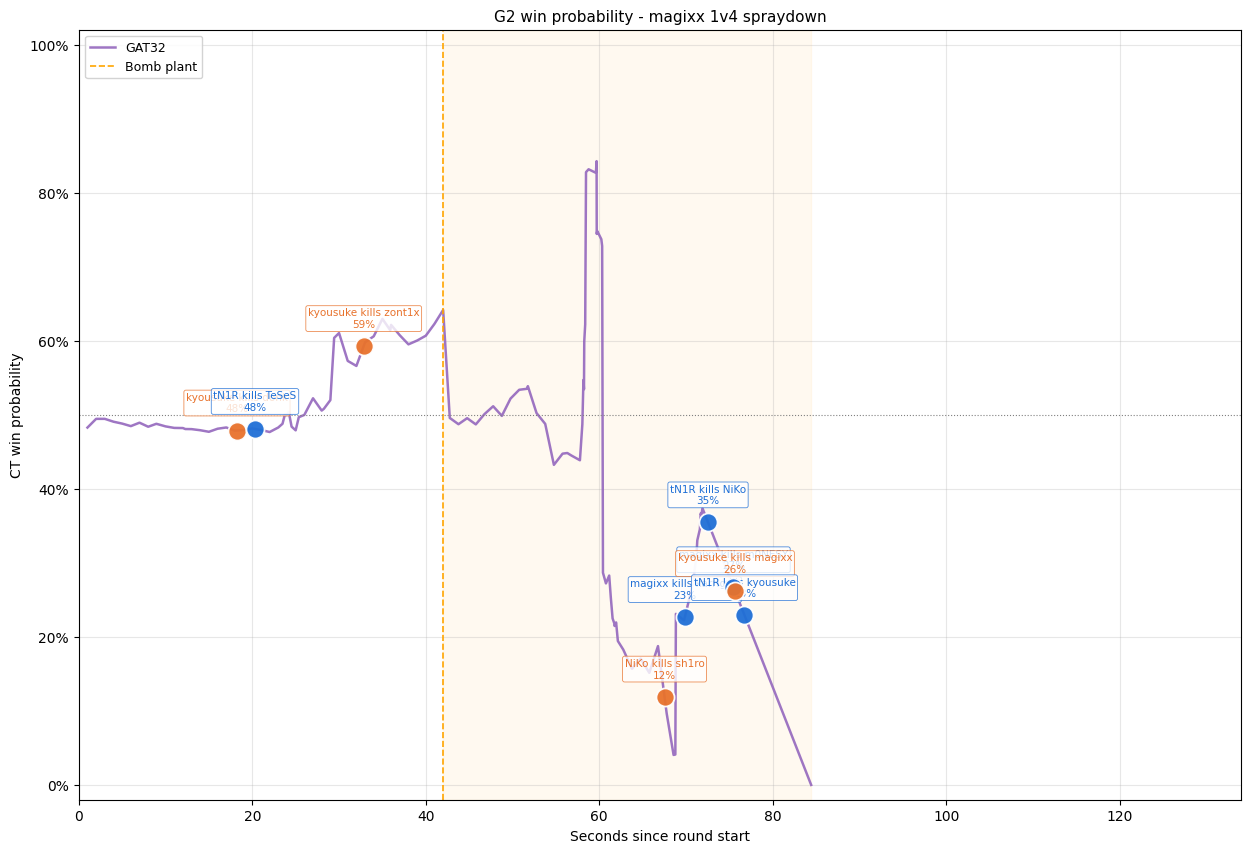

Saved → trace_dust2_r12.svg


In [11]:
# ── Plot ──────────────────────────────────────────────────────────────────
import matplotlib.ticker as mticker
fig, ax = plt.subplots(figsize=(15, 10))
import numpy as np

round_end_tick = int(_rounds.loc[_rounds['round_num'] == ROUND_NUM, 'end'].iloc[0])
t_end = (round_end_tick - FREEZE_END) / TICKS_PER_SECOND   # 187385 → ~126.9 s

times = np.append(np.asarray(times), t_end)
for name in trace:
    trace[name] = np.append(np.asarray(trace[name]), float(y_true))  # y_true=0 → 0% CT

for name, probs in trace.items():
    ax.plot(times, probs, label=name, color=COLORS[name],
            linewidth=1.8, alpha=0.9)

# Bomb plant vertical line
if plant_time is not None:
    ax.axvline(plant_time, color='orange', linestyle='--',
               linewidth=1.2, label='Bomb plant')

# 50% reference line
ax.axhline(0.5, color='gray', linestyle=':', linewidth=0.8)

# Shade post-plant region
if plant_time is not None:
    ax.axvspan(plant_time, max(times), alpha=0.06, color='orange')

# True outcome annotation
outcome_str = 'CT win' if y_true else 'T win'
ax.set_title(
    f'G2 win probability - magixx 1v4 spraydown',
    fontsize=11
)

import numpy as np


# Which model's curve the bubbles ride on
BUBBLE_MODEL = next(iter(trace))          # or e.g. 'GNN' / 'LightGBM'
bubble_probs = np.asarray(trace[BUBBLE_MODEL])
bubble_times = np.asarray(times)

KILL_COLORS = {'ct': '#1f6fd6', 't': '#e8722c'}   # blue = CT kill, orange = T kill

for _, kv in kills.iterrows():
    y = float(np.interp(kv['time'], bubble_times, bubble_probs))   # prob at kill time
    c = KILL_COLORS.get(kv['side'], 'gray')

    ax.scatter(kv['time'], y, s=170, color=c, edgecolor='white',
               linewidth=1.3, zorder=5, alpha=0.95)

    hs = '★' if kv['headshot'] else ''
    ax.annotate(f"{kv['attacker']} kills {kv['victim']}\n{y*100:.0f}%",
                xy=(kv['time'], y), xytext=(0, 12),
                textcoords='offset points', ha='center', va='bottom',
                fontsize=7.5, color=c,
                bbox=dict(boxstyle='round,pad=0.2', fc='white', ec=c, alpha=0.8, lw=0.6))

# legend entries for the bubbles
from matplotlib.lines import Line2D
ax._kill_handles = [
    Line2D([0], [0], marker='o', linestyle='', markersize=9,
           markerfacecolor=KILL_COLORS['ct'], markeredgecolor='white', label='CT kill'),
    Line2D([0], [0], marker='o', linestyle='', markersize=9,
           markerfacecolor=KILL_COLORS['t'],  markeredgecolor='white', label='T kill'),
]


ax.set_xlabel('Seconds since round start')
ax.set_ylabel('CT win probability')
ax.set_ylim(-0.02, 1.02)
ax.set_xlim(0, 134)
ax.yaxis.set_major_formatter(mticker.PercentFormatter(xmax=1))
ax.legend(loc='upper left', framealpha=0.85, fontsize=9)
ax.grid(True, alpha=0.3)

# plt.tight_layout()
# plt.savefig(f'trace_{MAP_NAME}_r{ROUND_NUM}.png', dpi=300, bbox_inches='tight')
# plt.show()
# print(f'Saved → trace_{MAP_NAME}_r{ROUND_NUM}.png')

# Save as SVG
svg_path = f'trace_{MAP_NAME}_r{ROUND_NUM}.svg'
plt.savefig(svg_path, format='svg', bbox_inches='tight')

# Optionally still save PNG too
plt.savefig(f'trace_{MAP_NAME}_r{ROUND_NUM}.png', dpi=300, bbox_inches='tight')

plt.show()
print(f'Saved → {svg_path}')


## 6. (Optional) Multi-Round Grid

Plot multiple rounds side-by-side for a quick overview of a full match.


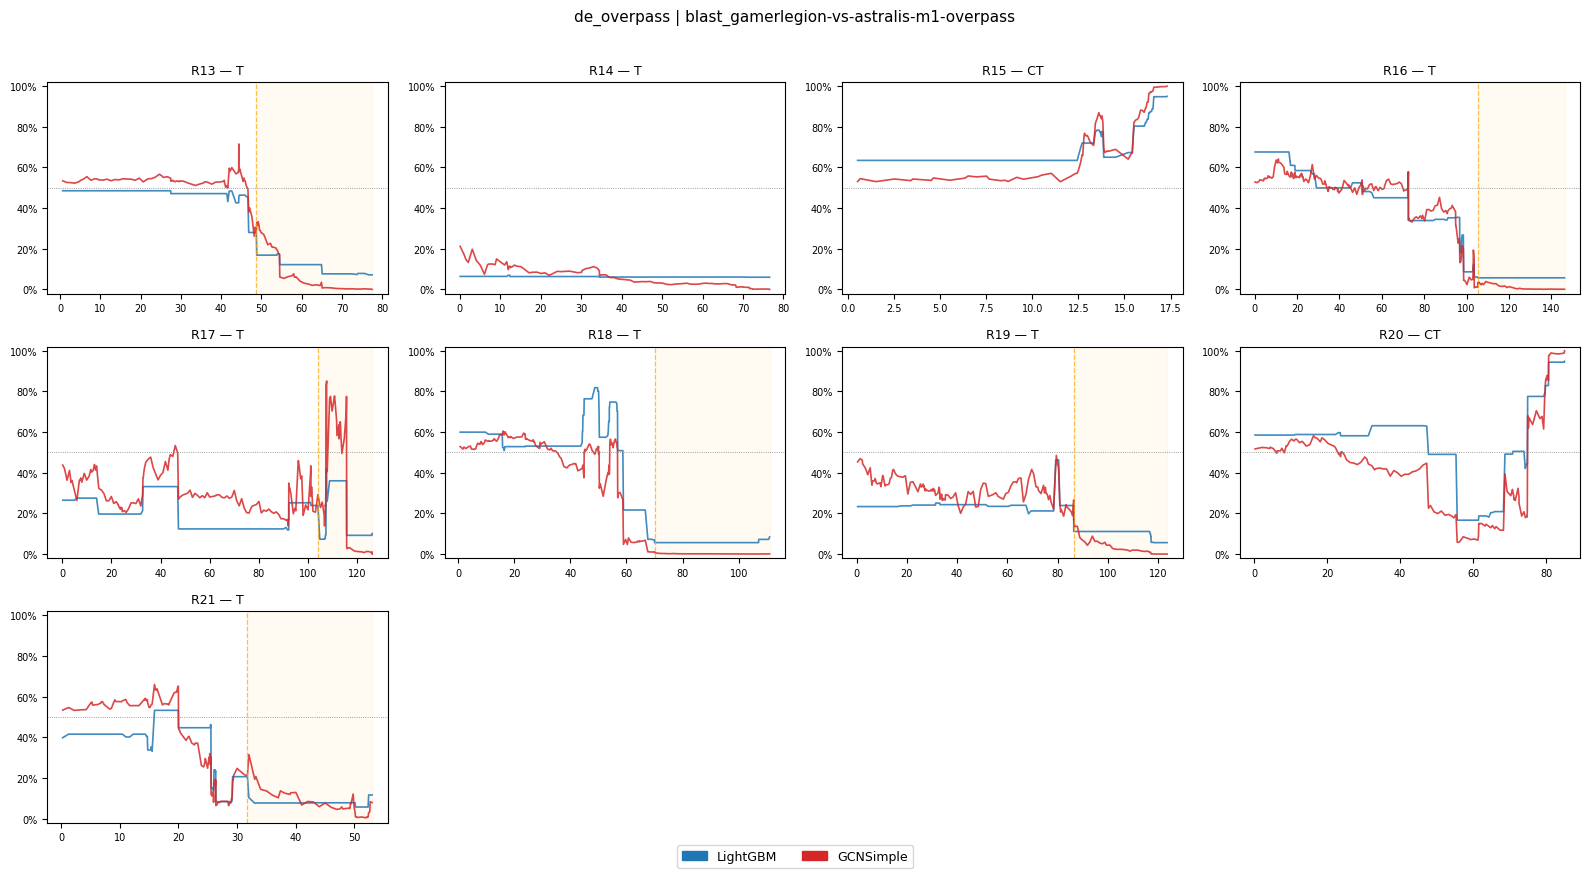

Saved grid plot.


In [ ]:
# ── CONFIG ────────────────────────────────────────────────────────────────
ROUNDS_TO_PLOT = list(range(13, 22))   # first 12 rounds; adjust as needed
COLS = 4
ROWS = -(-len(ROUNDS_TO_PLOT) // COLS)   # ceiling division

fig, axes = plt.subplots(ROWS, COLS, figsize=(COLS * 4, ROWS * 2.8))
axes = axes.flatten()

for ax_idx, rnum in enumerate(ROUNDS_TO_PLOT):
    ax = axes[ax_idx]
    ridx = [i for i, row in enumerate(match['df']) if row.get('roundNum') == rnum]
    if not ridx:
        ax.set_visible(False); continue

    ppd = max(
        (float(match['df'][i].get('secondsSincePhaseStart', 0))
         for i in ridx if not match['df'][i].get('bombPlanted', 0)),
        default=0.0
    )
    t_arr = [
        ppd + float(match['df'][i].get('secondsSincePhaseStart', 0))
        if match['df'][i].get('bombPlanted') else
        float(match['df'][i].get('secondsSincePhaseStart', 0))
        for i in ridx
    ]
    bomb_planted = any(match['df'][i].get('bombPlanted', 0) for i in ridx)
    y_r = int(match['Y'][ridx[0]])

    # Re-run inference for this round
    for name in list(MODELS_TO_RUN.keys()):
        if not MODELS_TO_RUN[name] or name not in loaded_models and name not in ['HP-diff']:
            continue
        if name == 'HP-diff':
            Xr = pd.DataFrame([match['df'][i] for i in ridx])
            dh = Xr['ctHp'].values - Xr['tHp'].values
            pr = np.clip(1 / (1 + np.exp(-dh / tau_opt)), 1e-7, 1-1e-7)
        elif name == 'LightGBM':
            Xr = pd.DataFrame([match['df'][i] for i in ridx])
            Xr = Xr.drop(columns=[c for c in ['tick','roundNum','ctWin'] if c in Xr], errors='ignore').fillna(0)
            pr = loaded_models['LightGBM'].predict(Xr)
        elif name in ['DeepSets','SetTransformer']:
            pr_list = []
            with torch.no_grad():
                for i in ridx:
                    xb = torch.tensor(normaliser.transform(np.array(match['X'][i], dtype=np.float32)),
                                      dtype=torch.float32).unsqueeze(0).to(DEVICE)
                    pr_list.append(torch.sigmoid(loaded_models[name](xb)).item())
            pr = np.array(pr_list)
        else:  # graph models
            pr_list = []
            with torch.no_grad():
                for i in ridx:
                    g = match['GNN'][i]
                    d = Batch.from_data_list([Data(
                        x=torch.tensor(g['x'], dtype=torch.float32),
                        edge_index=torch.tensor(g['edge_index'], dtype=torch.long),
                        edge_attr=torch.tensor(g['edge_attr'], dtype=torch.float32),
                    )]).to(DEVICE)
                    pr_list.append(torch.sigmoid(loaded_models[name](d)).item())
            pr = np.array(pr_list)

        ax.plot(t_arr, pr, color=COLORS[name], linewidth=1.2, alpha=0.85)

    if bomb_planted:
        ax.axvline(ppd, color='orange', linestyle='--', linewidth=0.9, alpha=0.7)
        ax.axvspan(ppd, max(t_arr), alpha=0.05, color='orange')

    ax.axhline(0.5, color='gray', linestyle=':', linewidth=0.6)
    ax.set_ylim(-0.02, 1.02)
    ax.set_title(f'R{rnum} — {"CT" if y_r else "T"}', fontsize=9)
    ax.tick_params(labelsize=7)
    ax.yaxis.set_major_formatter(mticker.PercentFormatter(xmax=1))

# Hide unused subplots
for ax in axes[len(ROUNDS_TO_PLOT):]:
    ax.set_visible(False)

# Shared legend
handles = [mpatches.Patch(color=COLORS[n], label=n)
           for n in MODELS_TO_RUN if MODELS_TO_RUN[n]]
fig.legend(handles=handles, loc='lower center', ncol=len(handles),
           fontsize=9, bbox_to_anchor=(0.5, -0.02))

fig.suptitle(f'de_{MAP_NAME} | {MATCH_KEY}', fontsize=11, y=1.01)
plt.tight_layout()
plt.savefig(f'grid_{MAP_NAME}_{MATCH_KEY[:20]}.png', dpi=150, bbox_inches='tight')
plt.show()
print('Saved grid plot.')
